# 1. Setup and configuration

In [1]:
import importlib
import importlib.metadata
import importlib.util
import os
import random
import subprocess
import sys
from pathlib import Path

# Runtime detection comes before the third-party imports, because Colab may need packages installed first
try:
    import google.colab  # noqa: F401
    IS_COLAB = True
except ImportError:
    IS_COLAB = "COLAB_RELEASE_TAG" in os.environ

# Install anything Colab is missing, at the versions used locally
COLAB_PACKAGES = {"monai": "1.6.1", "nibabel": "5.4.2"}
if IS_COLAB:
    _missing = [f"{name}=={version}" for name, version in COLAB_PACKAGES.items()
                if importlib.util.find_spec(name) is None]
    if _missing:
        print(f"Installing on Colab: {', '.join(_missing)}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
        importlib.invalidate_caches()

import monai
import numpy as np
import torch
from monai.utils import set_determinism

HAS_CUDA = torch.cuda.is_available()

MODE = "full" if IS_COLAB and HAS_CUDA else "dev"
_override = os.environ.get("HIPPO_MODE", "").strip().lower()
if _override:
    if _override not in ("dev", "full"):
        raise ValueError(f"HIPPO_MODE must be 'dev' or 'full', got {_override!r}")
    MODE = _override
if MODE == "full" and not HAS_CUDA:
    print("WARNING: full mode was forced but CUDA is not available. "
          "Running on the CPU with AMP off; training will be very slow.")

# Paths: repo root locally, /content on Colab, with the dataset and full-mode outputs on Drive
NOTEBOOK_NAME = "hippocampus_attention_unet.ipynb"
if IS_COLAB:
    ROOT = Path("/content")
    DRIVE_MOUNT = ROOT / "drive"
    DRIVE_ROOT = DRIVE_MOUNT / "MyDrive" / "decathlon"
else:
    _cwd = Path.cwd().resolve()
    ROOT = next((p for p in (_cwd, *_cwd.parents) if (p / NOTEBOOK_NAME).exists()), _cwd)
    DRIVE_ROOT = None

# Settings that must be identical in both modes
SHARED = {
    "seed": 42,
    "dataset_name": "Task04_Hippocampus",
    "n_cases": 260,
    "patch_size": (32, 32, 32),
    "channels": (16, 32, 64, 128),
    "strides": (2, 2, 2),
    "lr": 1e-3,
    "loss": "dicece",
    "sw_overlap": 0.5,
    "label_names": {0: "background", 1: "anterior", 2: "posterior"},
    "eval_batch_size": 1,  # full validation and test volumes differ in shape, so they cannot be batched
    # Baseline has no augmentation; the ablation runs override these
    "affine": False,
    "elastic": False,
    "aug_prob": 0.5,
}

# Scale settings (n_* = None means every case in that part of the split).
# batch_size counts patches; the DataLoader takes volumes_per_batch.
SCALE = {
    "dev": {
        "device": "cpu",
        "n_train": 20, "n_val": 5, "n_test": 5,
        "epochs": 3,
        "val_interval": 1,
        "batch_size": 2, "patches_per_volume": 2,
        "amp": False,
        "num_workers": 0, "pin_memory": False,
    },
    "full": {
        "device": "cuda" if HAS_CUDA else "cpu",
        "n_train": None, "n_val": None, "n_test": None,
        "epochs": 200,
        "val_interval": 5,
        "batch_size": 16, "patches_per_volume": 4,
        "amp": HAS_CUDA,
        "num_workers": 2, "pin_memory": True,
    },
}

_results_base = DRIVE_ROOT if IS_COLAB and MODE == "full" else ROOT
CFG = {
    "mode": MODE,
    **SHARED,
    **SCALE[MODE],
    "root_dir": ROOT,
    "data_dir": ROOT / "data",
    "dataset_dir": ROOT / "data" / SHARED["dataset_name"],
    "drive_dataset_dir": DRIVE_ROOT / "data" / SHARED["dataset_name"] if IS_COLAB else None,
    "output_dir": _results_base / "outputs" / MODE,
    "figures_dir": _results_base / "figures" if MODE == "full" else None,  # dev mode has no figures folder at all
    "split_file": ROOT / "splits" / "split.json",
}
CFG["volumes_per_batch"] = CFG["batch_size"] // CFG["patches_per_volume"]

# Google Drive holds the dataset and full-mode outputs on Colab
if IS_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT))

# Seeds
random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
set_determinism(seed=CFG["seed"])

# Start-up summary
_other_versions = ", ".join(f"{p} {importlib.metadata.version(p)}" for p in ("numpy", "nibabel", "matplotlib"))
print(f"Mode:       {CFG['mode']} (Colab: {IS_COLAB}, CUDA: {HAS_CUDA})")
print(f"Device:     {CFG['device']}")
print(f"GPU:        {torch.cuda.get_device_name(0) if HAS_CUDA else 'none'}")
print(f"Versions:   Python {sys.version.split()[0]}, torch {torch.__version__}, MONAI {monai.__version__}, {_other_versions}")
print(f"Data dir:   {CFG['dataset_dir']}")
if IS_COLAB:
    print(f"Drive data: {CFG['drive_dataset_dir']}")
print(f"Output dir: {CFG['output_dir']}")

Installing on Colab: monai==1.6.1
Mounted at /content/drive
Mode:       full (Colab: True, CUDA: True)
Device:     cuda
GPU:        NVIDIA L4
Versions:   Python 3.13.16, torch 2.14.1+cu130, MONAI 1.6.1, numpy 2.4.6, nibabel 5.4.2, matplotlib 3.10.0
Data dir:   /content/data/Task04_Hippocampus
Drive data: /content/drive/MyDrive/decathlon/data/Task04_Hippocampus
Output dir: /content/drive/MyDrive/decathlon/outputs/full


# 2. Data loading and exploration

In [2]:
# Locate the dataset. On Colab, copy it from Drive once per session and train from the copy.
import shutil

if CFG["dataset_dir"].is_dir():
    print(f"Using dataset at {CFG['dataset_dir']}")
elif IS_COLAB:
    if not CFG["drive_dataset_dir"].is_dir():
        raise FileNotFoundError(
            f"Dataset not found on Google Drive. Put the {CFG['dataset_name']} folder "
            f"(imagesTr, labelsTr, dataset.json) at {CFG['drive_dataset_dir']} and run this notebook again.")
    # Copy under a temporary name so that an interrupted copy never looks finished
    _partial = CFG["dataset_dir"].with_name(CFG["dataset_name"] + ".partial")
    shutil.rmtree(_partial, ignore_errors=True)
    print(f"Copying {CFG['drive_dataset_dir']} to {CFG['dataset_dir']} ...")
    shutil.copytree(CFG["drive_dataset_dir"], _partial)
    _partial.rename(CFG["dataset_dir"])
    print("Copy finished.")
else:
    raise FileNotFoundError(
        f"Dataset not found. Put the {CFG['dataset_name']} folder at {CFG['dataset_dir']}.")

Copying /content/drive/MyDrive/decathlon/data/Task04_Hippocampus to /content/data/Task04_Hippocampus ...
Copy finished.


In [3]:
# List the labelled cases, ignoring macOS junk files ("._*", ".DS_Store"). imagesTs is not used.
import re

CASE_PATTERN = re.compile(r"hippocampus_\d{3}\.nii\.gz")


def list_cases(folder):
    return sorted(p for p in folder.iterdir() if CASE_PATTERN.fullmatch(p.name))


IMAGE_PATHS = list_cases(CFG["dataset_dir"] / "imagesTr")
LABEL_PATHS = list_cases(CFG["dataset_dir"] / "labelsTr")

assert len(IMAGE_PATHS) == CFG["n_cases"], f"Expected {CFG['n_cases']} images, found {len(IMAGE_PATHS)}"
assert len(LABEL_PATHS) == CFG["n_cases"], f"Expected {CFG['n_cases']} labels, found {len(LABEL_PATHS)}"
_image_names = [p.name for p in IMAGE_PATHS]
_label_names = [p.name for p in LABEL_PATHS]
assert _image_names == _label_names, (
    f"Images and labels do not match one-to-one: {sorted(set(_image_names) ^ set(_label_names))[:10]}")
print(f"Found {len(IMAGE_PATHS)} image/label pairs, matched one-to-one.")

Found 260 image/label pairs, matched one-to-one.


In [4]:
# Scan every labelled case, then check dataset.json against the labels actually present
import json
from collections import Counter

import nibabel as nib


def read_ras(path):
    """Load a NIfTI file reoriented to RAS, so that axes mean the same thing in every case."""
    return nib.as_closest_canonical(nib.load(path))


shapes, spacings = [], []
intensity_min, intensity_max, intensity_sum, intensity_voxels = np.inf, -np.inf, 0.0, 0
label_counts = Counter()

for image_path, label_path in zip(IMAGE_PATHS, LABEL_PATHS):
    image_nii, label_nii = read_ras(image_path), read_ras(label_path)
    image, label = image_nii.get_fdata(), label_nii.get_fdata()
    assert image.shape == label.shape, f"Image and label shapes differ for {image_path.name}"

    shapes.append(image.shape)
    spacings.append(image_nii.header.get_zooms()[:3])
    intensity_min = min(intensity_min, image.min())
    intensity_max = max(intensity_max, image.max())
    intensity_sum += image.sum()
    intensity_voxels += image.size
    values, counts = np.unique(label, return_counts=True)
    label_counts.update(dict(zip(values.tolist(), counts.tolist())))

dataset_info = json.loads((CFG["dataset_dir"] / "dataset.json").read_text(encoding="utf-8"))
LABEL_MAP = {int(value): name.lower() for value, name in dataset_info["labels"].items()}
assert LABEL_MAP == CFG["label_names"], f"Unexpected labels in dataset.json: {LABEL_MAP}"
assert set(LABEL_MAP) == set(label_counts), (
    f"dataset.json lists {sorted(LABEL_MAP)} but labelsTr contains {sorted(label_counts)}")
print(f"Label map matches the values in labelsTr: {LABEL_MAP}")

Label map matches the values in labelsTr: {0: 'background', 1: 'anterior', 2: 'posterior'}


In [5]:
# Exploration report (all cases, also in dev mode)
shapes_arr = np.array(shapes)
spacings = np.array(spacings)
AXES = ("R-L", "A-P", "S-I")
SPACING_TOLERANCE_MM = 1e-3
_spacing_range = np.ptp(spacings, axis=0)
SPACING_CONSISTENT = bool(np.all(_spacing_range <= SPACING_TOLERANCE_MM))

print(f"Cases: {len(IMAGE_PATHS)}")
print(f"\nShape per axis {AXES}:")
print(f"  min {shapes_arr.min(axis=0).tolist()}, "
      f"median {np.median(shapes_arr, axis=0).tolist()}, max {shapes_arr.max(axis=0).tolist()}")
print("\nVoxel spacing per axis (mm):")
for i, axis_name in enumerate(AXES):
    print(f"  {axis_name}: min {spacings[:, i].min():.4f}, median {np.median(spacings[:, i]):.4f}, "
          f"max {spacings[:, i].max():.4f}, consistent: {bool(_spacing_range[i] <= SPACING_TOLERANCE_MM)}")
print(f"  Consistent across all cases: {SPACING_CONSISTENT}")
print(f"\nIntensity over all voxels: min {intensity_min:.1f}, max {intensity_max:.1f}, "
      f"mean {intensity_sum / intensity_voxels:.1f}")
print("\nClass balance (% of voxels over all labelsTr):")
_total_voxels = sum(label_counts.values())
for value, name in sorted(LABEL_MAP.items()):
    print(f"  {value} {name}: {100 * label_counts[value] / _total_voxels:.2f}%")

Cases: 260

Shape per axis ('R-L', 'A-P', 'S-I'):
  min [31, 40, 24], median [35.0, 50.0, 36.0], max [43, 59, 47]

Voxel spacing per axis (mm):
  R-L: min 1.0000, median 1.0000, max 1.0000, consistent: True
  A-P: min 1.0000, median 1.0000, max 1.0000, consistent: True
  S-I: min 1.0000, median 1.0000, max 1.0000, consistent: True
  Consistent across all cases: True

Intensity over all voxels: min 0.0, max 1704295.2, mean 27819.3

Class balance (% of voxels over all labelsTr):
  0 background: 94.75%
  1 anterior: 2.73%
  2 posterior: 2.52%


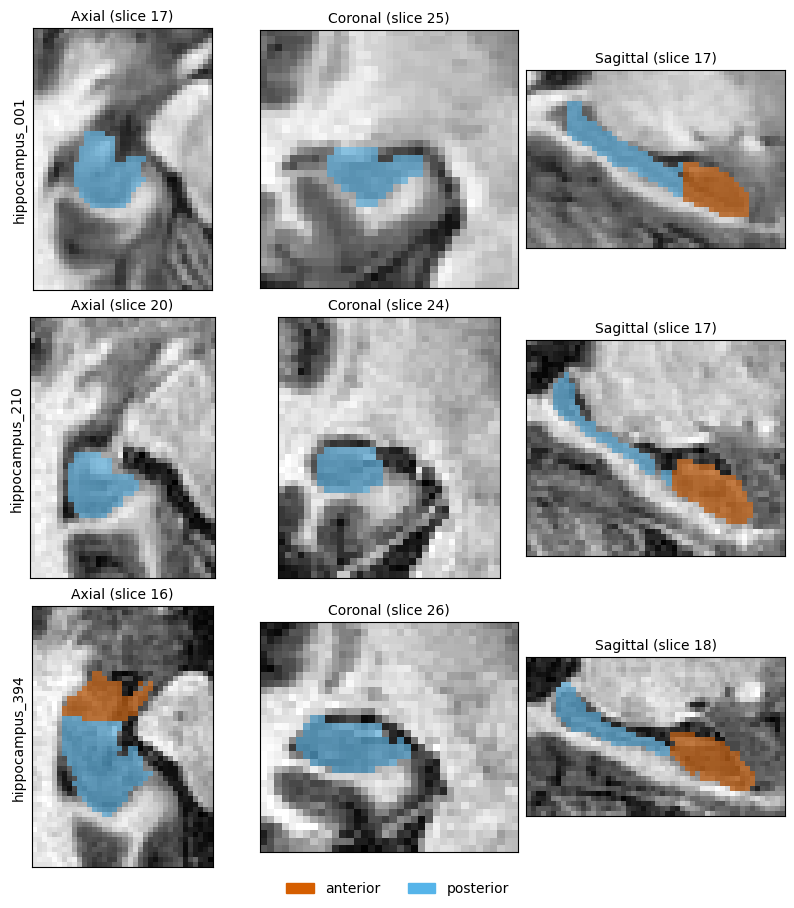

Saved to /content/drive/MyDrive/decathlon/outputs/full/exploration/example_slices.png


In [6]:
# Middle slices of 3 cases with the label overlaid
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

OVERLAY_COLOURS = {1: "#D55E00", 2: "#56B4E9"}  # anterior, posterior
VIEWS = {"Axial": 2, "Coronal": 1, "Sagittal": 0}  # slicing axis in RAS orientation

overlay_cmap = ListedColormap([OVERLAY_COLOURS[1], OVERLAY_COLOURS[2]])
plot_indices = np.linspace(0, len(IMAGE_PATHS) - 1, 3).round().astype(int)

fig, axes = plt.subplots(3, len(VIEWS), figsize=(8, 9), constrained_layout=True)
for row, case_index in enumerate(plot_indices):
    image = read_ras(IMAGE_PATHS[case_index]).get_fdata()
    label = read_ras(LABEL_PATHS[case_index]).get_fdata()
    for col, (view, axis) in enumerate(VIEWS.items()):
        middle = image.shape[axis] // 2
        ax = axes[row, col]
        ax.imshow(np.take(image, middle, axis=axis).T, cmap="gray", origin="lower",
                  vmin=0, vmax=np.percentile(image, 99.5), interpolation="nearest")
        ax.imshow(np.ma.masked_equal(np.take(label, middle, axis=axis).T, 0), cmap=overlay_cmap,
                  origin="lower", vmin=1, vmax=2, alpha=0.6, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"{view} (slice {middle})", fontsize=10)
    axes[row, 0].set_ylabel(IMAGE_PATHS[case_index].name.removesuffix(".nii.gz"), fontsize=10)

fig.legend(handles=[Patch(color=OVERLAY_COLOURS[k], label=LABEL_MAP[k]) for k in OVERLAY_COLOURS],
           loc="outside lower center", ncols=2, frameon=False)

exploration_dir = CFG["output_dir"] / "exploration"
exploration_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(exploration_dir / "example_slices.png", dpi=150)
plt.show()
print(f"Saved to {exploration_dir / 'example_slices.png'}")

In [7]:
# Conclusion
if SPACING_CONSISTENT:
    print(f"Conclusion: resampling is NOT needed; voxel spacing is consistent across all "
          f"{len(IMAGE_PATHS)} cases ({', '.join(f'{s:g}' for s in np.median(spacings, axis=0))} mm).")
else:
    print(f"Conclusion: resampling IS needed; voxel spacing varies across the "
          f"{len(IMAGE_PATHS)} cases (see the spacing report above).")

Conclusion: resampling is NOT needed; voxel spacing is consistent across all 260 cases (1, 1, 1 mm).


# 3. Train / validation / test split

The data is split **by subject (patient), not by case**, because one subject can contribute two cases.

MSD Task04 does not publish subject IDs, but the cases come in pairs: consecutive IDs (001-002, 003-004, ...) are two crops of the same brain scan, which fits the "left and right hippocampus" description in `dataset.json`. Across all 390 volumes (`imagesTr` and `imagesTs`) the IDs form 195 complete pairs, and the intensity scale within a pair is nearly identical (correlation 0.9999 of log 99th-percentile intensity, against about 0 for random pairs).

Both cases of a subject always go to the same set, so no person appears in both training and evaluation. The 260 labelled cases come from 170 subjects: 90 with both sides labelled and 80 with one.

In [8]:
# Load the fixed subject-level split, or generate it if it does not exist yet
import hashlib
import json
from collections import defaultdict

PARTS = ("train", "val", "test")
VAL_FRACTION = TEST_FRACTION = 0.15
# Fingerprint of the committed split; lets Colab confirm that a regenerated split is identical
EXPECTED_SPLIT_SHA256 = "e58b476884fb6718b15f0eb55578ff7ec0a083a38e201327a8294703889fcf6b"


def subject_of(case_name):
    """Consecutive IDs (001-002, 003-004, ...) are one subject."""
    number = int(case_name.removeprefix("hippocampus_").removesuffix(".nii.gz"))
    return (number + 1) // 2


def make_split(case_names, seed):
    """Shuffle subjects, not cases, and fill test and val first; train gets the rest."""
    cases_by_subject = defaultdict(list)
    for name in sorted(case_names):
        cases_by_subject[subject_of(name)].append(name)
    subjects = sorted(cases_by_subject)
    random.Random(seed).shuffle(subjects)

    split = {"seed": seed, "train": [], "val": [], "test": []}
    remaining = iter(subjects)
    for part, fraction in (("test", TEST_FRACTION), ("val", VAL_FRACTION)):
        while len(split[part]) < round(fraction * len(case_names)):
            split[part] += cases_by_subject[next(remaining)]
    for subject in remaining:
        split["train"] += cases_by_subject[subject]
    return split


def fingerprint(split):
    return hashlib.sha256(json.dumps(split, sort_keys=True).encode()).hexdigest()


case_names = [p.name for p in IMAGE_PATHS]
if CFG["split_file"].exists():
    split = json.loads(CFG["split_file"].read_text(encoding="utf-8"))
    print(f"Loaded split from {CFG['split_file']}")
else:
    split = make_split(case_names, CFG["seed"])
    if IS_COLAB:
        assert fingerprint(split) == EXPECTED_SPLIT_SHA256, (
            "The regenerated split differs from the committed splits/split.json.")
        print("Regenerated the split; it matches the committed one.")
    CFG["split_file"].parent.mkdir(parents=True, exist_ok=True)
    CFG["split_file"].write_text(json.dumps(split, indent=2) + "\n", encoding="utf-8")
    print(f"Saved split to {CFG['split_file']}")

# Checks: right seed, every case used, and no case or subject in two sets
assert split["seed"] == CFG["seed"], f"split.json uses seed {split['seed']}, CFG uses {CFG['seed']}"
assert sorted(sum((split[part] for part in PARTS), [])) == sorted(case_names), (
    "The split must contain every labelled case exactly once, so no case can be in two sets.")
_subjects = {part: {subject_of(name) for name in split[part]} for part in PARTS}
for _a, _b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not _subjects[_a] & _subjects[_b], f"Subjects appear in both {_a} and {_b}"

# Dev mode uses the first cases of each list; full mode (n_* = None) uses them all
SPLIT_CASES = {part: split[part][:CFG[f"n_{part}"]] for part in PARTS}
for part in PARTS:
    print(f"{part:5s}: using {len(SPLIT_CASES[part])} of {len(split[part])} cases "
          f"({len(_subjects[part])} subjects in the full list)")

Regenerated the split; it matches the committed one.
Saved split to /content/splits/split.json
train: using 182 of 182 cases (122 subjects in the full list)
val  : using 39 of 39 cases (24 subjects in the full list)
test : using 39 of 39 cases (24 subjects in the full list)


# 4. Transforms

In [9]:
# Transforms. Resampling is included only if the exploration found inconsistent voxel spacing.
from monai.transforms import (
    Compose,
    EnsureChannelFirstd,
    LoadImaged,
    NormalizeIntensityd,
    Orientationd,
    Rand3DElasticd,
    RandAffined,
    RandCropByPosNegLabeld,
    Spacingd,
    SpatialPadd,
)

KEYS = ("image", "label")
INTERPOLATION = ("bilinear", "nearest")  # bilinear is trilinear for 3D images; nearest keeps labels as integers
CFG["resample_spacing"] = None if SPACING_CONSISTENT else tuple(float(s) for s in np.median(spacings, axis=0))


def get_transforms(cfg, train):
    steps = [
        LoadImaged(keys=KEYS),
        EnsureChannelFirstd(keys=KEYS, channel_dim="no_channel"),
        Orientationd(keys=KEYS, axcodes="RAS"),
    ]
    if cfg["resample_spacing"] is not None:
        steps.append(Spacingd(keys=KEYS, pixdim=cfg["resample_spacing"], mode=INTERPOLATION))
    steps += [
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        SpatialPadd(keys=KEYS, spatial_size=cfg["patch_size"]),
    ]
    if not train:
        return Compose(steps)  # full volumes for sliding-window inference

    steps.append(RandCropByPosNegLabeld(keys=KEYS, label_key="label", spatial_size=cfg["patch_size"],
                                        pos=1, neg=1, num_samples=cfg["patches_per_volume"]))
    if cfg["affine"]:
        steps.append(RandAffined(keys=KEYS, prob=cfg["aug_prob"], mode=INTERPOLATION, padding_mode="border",
                                 rotate_range=[np.deg2rad(15)] * 3,  # +/-15 degrees
                                 scale_range=[0.1] * 3,              # factor 0.9-1.1
                                 translate_range=[3] * 3))           # +/-3 voxels on a 32-voxel patch
    if cfg["elastic"]:
        # Mild on purpose. Measured over 200 random draws, these settings move voxels by 0.3-1.3 voxels
        # RMS (median 0.6), and the largest move of any single voxel was about 2.2. The hippocampus is
        # small (median foreground bounding box 22 x 39 x 26 voxels), and the common tutorial range of
        # sigma 5-8, magnitude 100-200 moved voxels by up to 6.7.
        steps.append(Rand3DElasticd(keys=KEYS, prob=cfg["aug_prob"], mode=INTERPOLATION, padding_mode="border",
                                    sigma_range=(6, 8), magnitude_range=(50, 120)))
    return Compose(steps)

In [10]:
# Datasets and loaders. CacheDataset keeps the deterministic steps in memory; random steps run every epoch.
from monai.data import CacheDataset, DataLoader


def get_files(cfg, part):
    """Image and label paths for one part of the split ("train", "val" or "test")."""
    return [{"image": str(cfg["dataset_dir"] / "imagesTr" / name),
             "label": str(cfg["dataset_dir"] / "labelsTr" / name)} for name in SPLIT_CASES[part]]


def get_loader(cfg, part):
    """Build the loader for one part of the split."""
    train = part == "train"
    dataset = CacheDataset(get_files(cfg, part), transform=get_transforms(cfg, train), cache_rate=1.0,
                           num_workers=cfg["num_workers"], progress=False)
    # One training item yields patches_per_volume patches, so the DataLoader batches volumes
    return DataLoader(dataset, batch_size=cfg["volumes_per_batch"] if train else cfg["eval_batch_size"], shuffle=train,
                      num_workers=cfg["num_workers"], pin_memory=cfg["pin_memory"])

/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Labels stay valid after augmentation: found [0, 1, 2] across 728 augmented patches.
Batch shape: torch.Size([16, 1, 32, 32, 32])


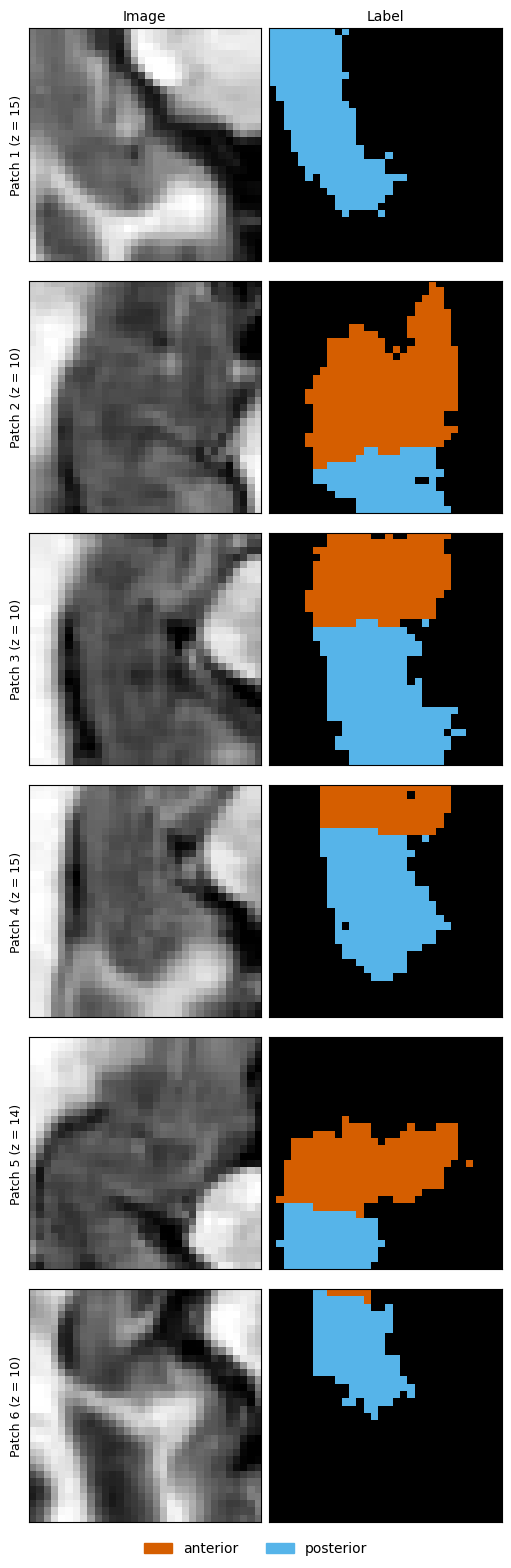

Saved to /content/drive/MyDrive/decathlon/outputs/full/checks/augmented_patches.png


In [11]:
# Visual check: training patches with affine and elastic both applied to every patch
CHECK_CFG = {**CFG, "affine": True, "elastic": True, "aug_prob": 1.0}
MAX_CHECK_PATCHES = 6

check_loader = get_loader(CHECK_CFG, "train")
allowed_labels = set(CFG["label_names"])
found_labels, n_checked, check_batch = set(), 0, None
for batch in check_loader:
    if check_batch is None:
        check_batch = batch
    found_labels |= set(np.unique(batch["label"].numpy()).tolist())
    n_checked += len(batch["label"])

assert found_labels <= allowed_labels, f"Augmentation produced invalid label values: {sorted(found_labels)}"
print(f"Labels stay valid after augmentation: found {sorted(int(v) for v in found_labels)} "
      f"across {n_checked} augmented patches.")

images = check_batch["image"].numpy()[:MAX_CHECK_PATCHES, 0]
labels = check_batch["label"].numpy()[:MAX_CHECK_PATCHES, 0]
print(f"Batch shape: {check_batch['image'].shape}")

label_cmap = ListedColormap(["#000000", OVERLAY_COLOURS[1], OVERLAY_COLOURS[2]])
fig, axes = plt.subplots(len(images), 2, figsize=(5, 2.6 * len(images)), squeeze=False, constrained_layout=True)
for row, (image, label) in enumerate(zip(images, labels)):
    slice_z = int((label > 0).sum(axis=(0, 1)).argmax())  # axial slice with the most foreground
    image_slice, label_slice = image[:, :, slice_z].T, label[:, :, slice_z].T
    axes[row, 0].imshow(image_slice, cmap="gray", origin="lower", interpolation="nearest",
                        vmin=np.percentile(image_slice, 1), vmax=np.percentile(image_slice, 99))
    axes[row, 1].imshow(label_slice, cmap=label_cmap, origin="lower", vmin=0, vmax=2, interpolation="nearest")
    axes[row, 0].set_ylabel(f"Patch {row + 1} (z = {slice_z})", fontsize=9)
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_title("Image", fontsize=10)
axes[0, 1].set_title("Label", fontsize=10)
fig.legend(handles=[Patch(color=OVERLAY_COLOURS[k], label=LABEL_MAP[k]) for k in OVERLAY_COLOURS],
           loc="outside lower center", ncols=2, frameon=False)

checks_dir = CFG["output_dir"] / "checks"
checks_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(checks_dir / "augmented_patches.png", dpi=150)
plt.show()
print(f"Saved to {checks_dir / 'augmented_patches.png'}")

# 5. Model and loss

### Attention gates

A U-Net's skip connections copy fine spatial detail from the encoder to the decoder, but they pass everything along, including irrelevant background. An attention gate on each skip connection filters those features before they are concatenated.

Each gate takes two inputs: the skip features and a **gating signal from the coarser level** of the decoder, which has seen more context about where the target is. The two are projected to a common number of channels and brought to the same size, added together and passed through a ReLU, then a 1 × 1 × 1 convolution and a sigmoid. The result is an attention coefficient between 0 and 1 for every voxel. Multiplying the skip features by these coefficients **re-weights the skip connection**, keeping the regions relevant to the target and suppressing the rest.

Reference: Oktay et al. 2018, *Attention U-Net: Learning Where to Look for the Pancreas*, arXiv:1804.03999.

In [12]:
# 3D Attention U-Net. The network outputs raw logits; the loss and metrics apply softmax themselves.
from monai.networks.nets import AttentionUnet


def build_model(cfg):
    model = AttentionUnet(spatial_dims=3, in_channels=1, out_channels=len(cfg["label_names"]),
                          channels=cfg["channels"], strides=cfg["strides"])
    return model.to(cfg["device"])

In [13]:
# Model checks: patch-sized forward pass for both widths, then sliding-window inference on a full volume
from monai.inferers import sliding_window_inference

WIDE_CHANNELS = (32, 64, 128, 256)  # run 8
_n_classes = len(CFG["label_names"])

for _name, _channels in (("baseline", CFG["channels"]), ("wide (run 8)", WIDE_CHANNELS)):
    _model = build_model({**CFG, "channels": _channels}).eval()
    with torch.no_grad():
        _output = _model(torch.zeros(1, 1, *CFG["patch_size"], device=CFG["device"]))
    assert tuple(_output.shape) == (1, _n_classes, *CFG["patch_size"]), f"Unexpected output shape {_output.shape}"
    _n_params = sum(p.numel() for p in _model.parameters())
    print(f"{_name}: channels {_channels}, output {tuple(_output.shape)}, {_n_params:,} parameters")

_model = build_model(CFG).eval()
_volume = next(iter(get_loader(CFG, "val")))["image"].to(CFG["device"])
with torch.no_grad():
    _output = sliding_window_inference(_volume, roi_size=CFG["patch_size"], sw_batch_size=CFG["batch_size"],
                                       predictor=_model, overlap=CFG["sw_overlap"])
assert tuple(_output.shape) == (1, _n_classes, *_volume.shape[2:]), f"Unexpected output shape {_output.shape}"
print(f"Sliding window: input {tuple(_volume.shape)}, output {tuple(_output.shape)}")

baseline: channels (16, 32, 64, 128), output (1, 3, 32, 32, 32), 1,466,583 parameters
wide (run 8): channels (32, 64, 128, 256), output (1, 3, 32, 32, 32), 5,860,767 parameters
Sliding window: input (1, 1, 32, 47, 32), output (1, 3, 32, 47, 32)


### Loss functions

The baseline loss is Dice + cross-entropy (`DiceCELoss`). Run 7 replaces it with class-weighted cross-entropy.

The class weights follow the class-balancing term of the U-Net weight map (Ronneberger et al. 2015, *U-Net: Convolutional Networks for Biomedical Image Segmentation*, Section 3, arXiv:1505.04597). We use inverse class frequency, computed over the **training** labels only (full volumes, before cropping) and normalised so the weights sum to the number of classes. We **omit the border term** of that weight map, which adds extra weight between touching objects.

In [14]:
# Inverse-class-frequency weights over the training labels only
def compute_class_weights(train_files):
    """Weights from full training label volumes (before cropping), normalised to sum to the number of classes.

    The result is cached in the output folder and reused only if the same training files were used.
    """
    names = sorted(Path(f["label"]).name for f in train_files)
    files_key = hashlib.sha256("\n".join(names).encode()).hexdigest()
    cache_path = CFG["output_dir"] / "class_weights.json"
    if cache_path.exists():
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        if cached["train_files_sha256"] == files_key:
            print(f"Loaded class weights from {cache_path}")
            return cached["weights"]

    counts = Counter()
    for f in train_files:
        values, voxels = np.unique(nib.load(f["label"]).get_fdata(), return_counts=True)
        counts.update(dict(zip(values.tolist(), voxels.tolist())))
    classes = sorted(CFG["label_names"])
    assert set(counts) == set(classes), f"Training labels contain {sorted(counts)}, expected {classes}"

    total = sum(counts.values())
    inverse_frequency = [total / counts[c] for c in classes]
    weights = [w * len(classes) / sum(inverse_frequency) for w in inverse_frequency]

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    cache_path.write_text(json.dumps({"train_files_sha256": files_key, "n_files": len(names),
                                      "voxel_counts": [counts[c] for c in classes], "weights": weights}, indent=2),
                          encoding="utf-8")
    print(f"Computed class weights from {len(names)} training volumes; saved to {cache_path}")
    return weights


CLASS_WEIGHTS = compute_class_weights(get_files(CFG, "train"))
for value, weight in zip(sorted(CFG["label_names"]), CLASS_WEIGHTS):
    print(f"  {value} {CFG['label_names'][value]}: {weight:.4f}")

Loaded class weights from /content/drive/MyDrive/decathlon/outputs/full/class_weights.json
  0 background: 0.0407
  1 anterior: 1.4082
  2 posterior: 1.5511


In [15]:
# Loss functions, chosen by CFG["loss"]. Both take raw logits (B,C,D,H,W) and labels (B,1,D,H,W).
from monai.losses import DiceCELoss


def build_loss(cfg, class_weights=None):
    if cfg["loss"] == "dicece":
        return DiceCELoss(to_onehot_y=True, softmax=True)
    if cfg["loss"] == "weighted_ce":
        weight = torch.as_tensor(class_weights, dtype=torch.float32, device=cfg["device"])
        cross_entropy = torch.nn.CrossEntropyLoss(weight=weight)

        def weighted_ce(outputs, labels):
            return cross_entropy(outputs, labels.squeeze(1).long())  # CrossEntropyLoss wants (B,D,H,W) long

        return weighted_ce
    raise ValueError(f"Unknown loss {cfg['loss']!r}; expected 'dicece' or 'weighted_ce'")

# 6. Training and validation functions

In [16]:
# One training epoch on patches, and one validation pass on full volumes
from monai.metrics import DiceMetric
from monai.networks.utils import one_hot


def train_one_epoch(model, loader, loss_fn, optimizer, scaler, cfg):
    """Return the mean loss per patch. AMP and the scaler are active only if cfg["amp"] is on."""
    model.train()
    total_loss, n_patches = 0.0, 0
    for batch in loader:
        images = batch["image"].to(cfg["device"], non_blocking=cfg["pin_memory"])
        labels = batch["label"].to(cfg["device"], non_blocking=cfg["pin_memory"])
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=cfg["device"], enabled=cfg["amp"]):
            loss = loss_fn(model(images), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
        n_patches += len(images)
    return total_loss / n_patches


def validate(model, loader, loss_fn, cfg, compute_dice):
    """Sliding-window inference on full volumes. Return (mean loss, Dice dict or None).

    The loss is always computed. Dice is computed only if compute_dice is True.
    """
    model.eval()
    n_classes = len(cfg["label_names"])
    dice_metric = DiceMetric(include_background=False, reduction="mean_batch")
    total_loss = 0.0
    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(cfg["device"], non_blocking=cfg["pin_memory"])
            labels = batch["label"].to(cfg["device"], non_blocking=cfg["pin_memory"])
            with torch.autocast(device_type=cfg["device"], enabled=cfg["amp"]):
                logits = sliding_window_inference(images, roi_size=cfg["patch_size"], sw_batch_size=cfg["batch_size"],
                                                  predictor=model, overlap=cfg["sw_overlap"])
                total_loss += loss_fn(logits, labels).item()
            if compute_dice:
                predictions = torch.argmax(logits, dim=1, keepdim=True)
                dice_metric(y_pred=one_hot(predictions, num_classes=n_classes, dim=1),
                            y=one_hot(labels.long(), num_classes=n_classes, dim=1))
    val_loss = total_loss / len(loader)
    if not compute_dice:
        return val_loss, None

    per_class = dice_metric.aggregate().tolist()
    foreground_names = [cfg["label_names"][value] for value in sorted(cfg["label_names"]) if value != 0]
    val_dice = dict(zip(foreground_names, per_class))
    val_dice["mean"] = float(np.mean(per_class))
    return val_loss, val_dice

In [17]:
# One complete training run. best.pt and history.json go to CFG output dir/<run_name>/.
import time


def _write_json(path, data):
    """Write through a temporary file, so that a crash during writing cannot damage the existing file."""
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(data, indent=2), encoding="utf-8")
    temporary.replace(path)


def train_run(cfg, run_name):
    set_determinism(seed=cfg["seed"])  # every run starts from the same random state
    run_dir = cfg["output_dir"] / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    train_loader, val_loader = get_loader(cfg, "train"), get_loader(cfg, "val")
    model = build_model(cfg)
    loss_fn = build_loss(cfg, CLASS_WEIGHTS)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    scaler = torch.amp.GradScaler(cfg["device"], enabled=cfg["amp"])

    history = {"run_name": run_name, "best_epoch": None, "best_val_dice": None, "epochs": []}
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, scaler, cfg)
        measure_dice = epoch % cfg["val_interval"] == 0
        val_loss, val_dice = validate(model, val_loader, loss_fn, cfg, compute_dice=measure_dice)

        is_best = val_dice is not None and (history["best_val_dice"] is None
                                            or val_dice["mean"] > history["best_val_dice"])
        if is_best:
            history["best_epoch"], history["best_val_dice"] = epoch, val_dice["mean"]
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_dice": val_dice}, run_dir / "best.pt")

        seconds = time.time() - start
        history["epochs"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                                  "val_dice": val_dice, "seconds": seconds})
        _write_json(run_dir / "history.json", history)  # after every epoch, so a crash keeps what was done

        dice_text = ""
        if val_dice is not None:
            dice_text = (f"  Dice ant {val_dice['anterior']:.3f} post {val_dice['posterior']:.3f} "
                         f"mean {val_dice['mean']:.3f}{' *' if is_best else ''}")
        print(f"[{run_name}] epoch {epoch}/{cfg['epochs']}  train {train_loss:.4f}  val {val_loss:.4f}"
              f"{dice_text}  ({seconds:.1f}s)")

    print(f"[{run_name}] best mean val Dice {history['best_val_dice']:.4f} at epoch {history['best_epoch']}")
    return history

In [18]:
# Smoke test: one baseline run, in dev mode only (in full mode this would be a complete training run)
LOSS_COLOURS = {"train": "#009E73", "val": "#CC79A7"}  # kept distinct from the anterior/posterior colours

if CFG["mode"] == "dev":
    smoke_history = train_run(CFG, "smoke_test")

    _epochs = [e["epoch"] for e in smoke_history["epochs"]]
    fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
    ax.plot(_epochs, [e["train_loss"] for e in smoke_history["epochs"]], marker="o", color=LOSS_COLOURS["train"], label="Training loss")
    ax.plot(_epochs, [e["val_loss"] for e in smoke_history["epochs"]], marker="o", color=LOSS_COLOURS["val"], label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(_epochs)
    ax.set_title("smoke_test: loss curves", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.show()
else:
    print("Skipping the smoke test because this is full mode.")

Skipping the smoke test because this is full mode.


# 7. Ablation loop

In [19]:
# Ablation plan: each run is a set of overrides on top of BASELINE
BASELINE = {key: CFG[key] for key in ("affine", "elastic", "lr", "loss", "channels")}

FIXED_RUNS = [
    ("run1_baseline", {}),
    ("run2_affine", {"affine": True}),
    ("run3_elastic", {"elastic": True}),
    ("run4_affine_elastic", {"affine": True, "elastic": True}),
]
LR_RUNS = [("run5_lr_1e-4", 1e-4), ("run6_lr_3e-3", 3e-3)]


def best_run(val_results, candidates):
    """Return the candidate with the highest best validation Dice, and a printable ranking.

    TEST METRICS MUST NEVER FEED ANY DECISION. val_results may hold only validation-side fields,
    and this assert stops the run if anything else reaches a decision.
    """
    for name in candidates:
        assert set(val_results[name]) == {"best_val_dice", "overrides"}, (
            f"Only validation results may feed decisions, but {name} has {sorted(val_results[name])}")
    winner = max(candidates, key=lambda name: val_results[name]["best_val_dice"])
    ranking = ", ".join(f"{name} {val_results[name]['best_val_dice']:.4f}" for name in candidates)
    return winner, ranking


def iter_runs(val_results):
    """Yield (run_name, overrides, reason). Runs 5-8 are resolved only when reached, from validation results."""
    for name, overrides in FIXED_RUNS:
        yield name, overrides, "fixed configuration"

    candidates = [name for name, _ in FIXED_RUNS]
    best_aug, ranking = best_run(val_results, candidates)
    reason = f"inherits {best_aug}, the best of runs 1-4 by validation Dice ({ranking})"
    for name, lr in LR_RUNS:
        yield name, {**val_results[best_aug]["overrides"], "lr": lr}, reason

    candidates += [name for name, _ in LR_RUNS]
    best_so_far, ranking = best_run(val_results, candidates)
    yield ("run7_weighted_ce", {**val_results[best_so_far]["overrides"], "loss": "weighted_ce"},
           f"inherits {best_so_far}, the best of runs 1-6 by validation Dice ({ranking})")

    candidates += ["run7_weighted_ce"]
    best_so_far, ranking = best_run(val_results, candidates)
    yield ("run8_wide", {**val_results[best_so_far]["overrides"], "channels": WIDE_CHANNELS},
           f"inherits {best_so_far}, the best of runs 1-7 by validation Dice ({ranking})")

In [20]:
# Test-set evaluation of one finished run, and the run's plots
import csv


def evaluate_test(cfg, run_name):
    """Load best.pt, evaluate the test split once, and write test_per_case.csv. Return the test results."""
    run_dir = cfg["output_dir"] / run_name
    checkpoint = torch.load(run_dir / "best.pt", map_location=cfg["device"], weights_only=True)
    model = build_model(cfg)
    model.load_state_dict(checkpoint["model"])
    model.eval()

    n_classes = len(cfg["label_names"])
    dice_metric = DiceMetric(include_background=False, reduction="none")
    loader = get_loader(cfg, "test")
    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(cfg["device"], non_blocking=cfg["pin_memory"])
            labels = batch["label"].to(cfg["device"], non_blocking=cfg["pin_memory"])
            with torch.autocast(device_type=cfg["device"], enabled=cfg["amp"]):
                logits = sliding_window_inference(images, roi_size=cfg["patch_size"], sw_batch_size=cfg["batch_size"],
                                                  predictor=model, overlap=cfg["sw_overlap"])
            predictions = torch.argmax(logits, dim=1, keepdim=True)
            dice_metric(y_pred=one_hot(predictions, num_classes=n_classes, dim=1),
                        y=one_hot(labels.long(), num_classes=n_classes, dim=1))

    per_class = dice_metric.aggregate().cpu().numpy()  # one row per case, one column per foreground class
    case_names = SPLIT_CASES["test"]
    assert len(case_names) == len(per_class), "Test loader and test case list differ in length"
    names = [cfg["label_names"][value] for value in sorted(cfg["label_names"]) if value != 0]
    per_case = [{"case": case, **dict(zip(names, row.tolist())), "mean": float(row.mean())}
                for case, row in zip(case_names, per_class)]

    with open(run_dir / "test_per_case.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["case", *names, "mean"])
        writer.writeheader()
        writer.writerows(per_case)

    summary = {key: {"mean": float(np.mean([row[key] for row in per_case])),
                     "std": float(np.std([row[key] for row in per_case], ddof=1))} for key in [*names, "mean"]}
    print(f"[{run_name}] test Dice " + "  ".join(f"{k} {v['mean']:.3f} +/- {v['std']:.3f}" for k, v in summary.items()))
    return {"n_cases": len(per_case), "summary": summary, "per_case": per_case}


def save_run_plots(history, run_dir):
    """Save the run's loss curves and validation Dice curves."""
    epochs = [e["epoch"] for e in history["epochs"]]
    fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
    ax.plot(epochs, [e["train_loss"] for e in history["epochs"]], color=LOSS_COLOURS["train"], label="Training loss")
    ax.plot(epochs, [e["val_loss"] for e in history["epochs"]], color=LOSS_COLOURS["val"], label="Validation loss")
    ax.set(xlabel="Epoch", ylabel="Loss", title=f"{history['run_name']}: loss")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.savefig(run_dir / "loss.png", dpi=150)
    plt.close(fig)

    measured = [e for e in history["epochs"] if e["val_dice"] is not None]
    fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
    for key, colour in (("anterior", OVERLAY_COLOURS[1]), ("posterior", OVERLAY_COLOURS[2]), ("mean", "#222222")):
        ax.plot([e["epoch"] for e in measured], [e["val_dice"][key] for e in measured], color=colour, label=key.capitalize())
    ax.set(xlabel="Epoch", ylabel="Validation Dice", title=f"{history['run_name']}: validation Dice", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.savefig(run_dir / "dice.png", dpi=150)
    plt.close(fig)

In [21]:
# The ablation loop: train, test once, save, and carry only validation results forward
def run_ablation(cfg):
    val_results, all_results = {}, {}
    RUNS = []  # (run_name, overrides), filled in as each later run is resolved
    for run_name, overrides, reason in iter_runs(val_results):
        assert set(overrides) <= set(BASELINE), f"{run_name} changes settings outside the ablation: {overrides}"
        print(f"\n=== {run_name}: {reason}\n    overrides: {overrides}")
        run_cfg = {**cfg, **BASELINE, **overrides}
        run_dir = cfg["output_dir"] / run_name
        results_path = run_dir / "results.json"

        if results_path.exists():
            saved = json.loads(results_path.read_text(encoding="utf-8"))
            assert saved["epochs"] == run_cfg["epochs"], (
                f"{results_path} was trained for {saved['epochs']} epochs, but this run needs {run_cfg['epochs']}. "
                "All runs must use the same number of epochs, so move the old results out of the output folder first.")
            assert saved["overrides"] == json.loads(json.dumps(overrides)), (
                f"{results_path} used {saved['overrides']}, but the validation results now give {overrides}. "
                "Move this run and all later runs out of the output folder to rerun them.")
            print("    results.json exists; skipping this run.")
        else:
            history = train_run(run_cfg, run_name)
            test_results = evaluate_test(run_cfg, run_name)  # the checkpoint was already chosen by validation Dice
            save_run_plots(history, run_dir)
            saved = {"run_name": run_name, "reason": reason, "overrides": overrides, "epochs": run_cfg["epochs"],
                     "best_epoch": history["best_epoch"], "best_val_dice": history["best_val_dice"],
                     "test": test_results}
            _write_json(results_path, saved)  # written last, so an interrupted run is simply redone

        all_results[run_name] = saved
        # Only these two validation-side fields are passed on to the decisions for later runs
        val_results[run_name] = {"best_val_dice": saved["best_val_dice"], "overrides": saved["overrides"]}
        RUNS.append((run_name, overrides))
    print(f"\nAblation finished: {len(RUNS)} runs in {cfg['output_dir']}")
    return all_results

In [22]:
# Run the ablation. Finished runs are skipped, so this cell can simply be run again after a disconnect.
ABLATION_RESULTS = run_ablation(CFG)


=== run1_baseline: fixed configuration
    overrides: {}
    results.json exists; skipping this run.

=== run2_affine: fixed configuration
    overrides: {'affine': True}
    results.json exists; skipping this run.

=== run3_elastic: fixed configuration
    overrides: {'elastic': True}
    results.json exists; skipping this run.

=== run4_affine_elastic: fixed configuration
    overrides: {'affine': True, 'elastic': True}
    results.json exists; skipping this run.

=== run5_lr_1e-4: inherits run4_affine_elastic, the best of runs 1-4 by validation Dice (run1_baseline 0.8871, run2_affine 0.8900, run3_elastic 0.8900, run4_affine_elastic 0.8921)
    overrides: {'affine': True, 'elastic': True, 'lr': 0.0001}
    results.json exists; skipping this run.

=== run6_lr_3e-3: inherits run4_affine_elastic, the best of runs 1-4 by validation Dice (run1_baseline 0.8871, run2_affine 0.8900, run3_elastic 0.8900, run4_affine_elastic 0.8921)
    overrides: {'affine': True, 'elastic': True, 'lr': 0.003

# 8. Evaluation

In [23]:
# Results table, built from the files saved in each run folder
RESULT_PATHS = sorted(CFG["output_dir"].glob("run*/results.json"))
assert len(RESULT_PATHS) == 8, f"Expected 8 finished runs in {CFG['output_dir']}, found {len(RESULT_PATHS)}"
ALL_RESULTS = {p.parent.name: json.loads(p.read_text(encoding="utf-8")) for p in RESULT_PATHS}
ALL_HISTORIES = {name: json.loads((CFG["output_dir"] / name / "history.json").read_text(encoding="utf-8"))
                 for name in ALL_RESULTS}

# The final model is chosen by validation Dice only
FINAL_RUN = max(ALL_RESULTS, key=lambda name: ALL_RESULTS[name]["best_val_dice"])


def describe_overrides(overrides):
    """Short human-readable description of a run's changes from the baseline."""
    parts = [name for name in ("affine", "elastic") if overrides.get(name)]
    if "lr" in overrides:
        parts.append(f"lr {overrides['lr']:.0e}".replace("e-0", "e-"))
    if "loss" in overrides:
        parts.append("weighted CE")
    if "channels" in overrides:
        parts.append(f"channels {overrides['channels'][0]}-{overrides['channels'][-1]}")
    return ", ".join(parts) or "baseline"


def _mean_std(results, key):
    summary = results["test"]["summary"][key]
    return f"{summary['mean']:.3f} ± {summary['std']:.3f}"


table_lines = ["| Run | Config change | Val mean Dice | Test anterior | Test posterior | Test mean |",
               "|---|---|---|---|---|---|"]
for name, results in ALL_RESULTS.items():
    table_lines.append(f"| {name} | {describe_overrides(results['overrides'])} | {results['best_val_dice']:.3f} "
                       f"| {_mean_std(results, 'anterior')} | {_mean_std(results, 'posterior')} "
                       f"| {_mean_std(results, 'mean')} |")
_n_test = ALL_RESULTS[FINAL_RUN]["test"]["n_cases"]
table_lines += ["", f"Test Dice is mean ± standard deviation across {_n_test} test cases. "
                    f"Final model (highest validation Dice): **{FINAL_RUN}**."]
results_table = "\n".join(table_lines) + "\n"

(CFG["output_dir"] / "results_table.md").write_text(results_table, encoding="utf-8")
print(results_table)

| Run | Config change | Val mean Dice | Test anterior | Test posterior | Test mean |
|---|---|---|---|---|---|
| run1_baseline | baseline | 0.887 | 0.896 ± 0.039 | 0.882 ± 0.040 | 0.889 ± 0.037 |
| run2_affine | affine | 0.890 | 0.894 ± 0.039 | 0.880 ± 0.043 | 0.887 ± 0.039 |
| run3_elastic | elastic | 0.890 | 0.900 ± 0.039 | 0.877 ± 0.040 | 0.889 ± 0.037 |
| run4_affine_elastic | affine, elastic | 0.892 | 0.900 ± 0.039 | 0.881 ± 0.039 | 0.891 ± 0.037 |
| run5_lr_1e-4 | affine, elastic, lr 1e-4 | 0.890 | 0.900 ± 0.039 | 0.881 ± 0.039 | 0.890 ± 0.036 |
| run6_lr_3e-3 | affine, elastic, lr 3e-3 | 0.891 | 0.898 ± 0.036 | 0.880 ± 0.038 | 0.889 ± 0.035 |
| run7_weighted_ce | affine, elastic, weighted CE | 0.819 | 0.844 ± 0.037 | 0.808 ± 0.033 | 0.826 ± 0.033 |
| run8_wide | affine, elastic, channels 32-256 | 0.894 | 0.896 ± 0.038 | 0.882 ± 0.041 | 0.889 ± 0.037 |

Test Dice is mean ± standard deviation across 39 test cases. Final model (highest validation Dice): **run8_wide**.



# 9. Figures

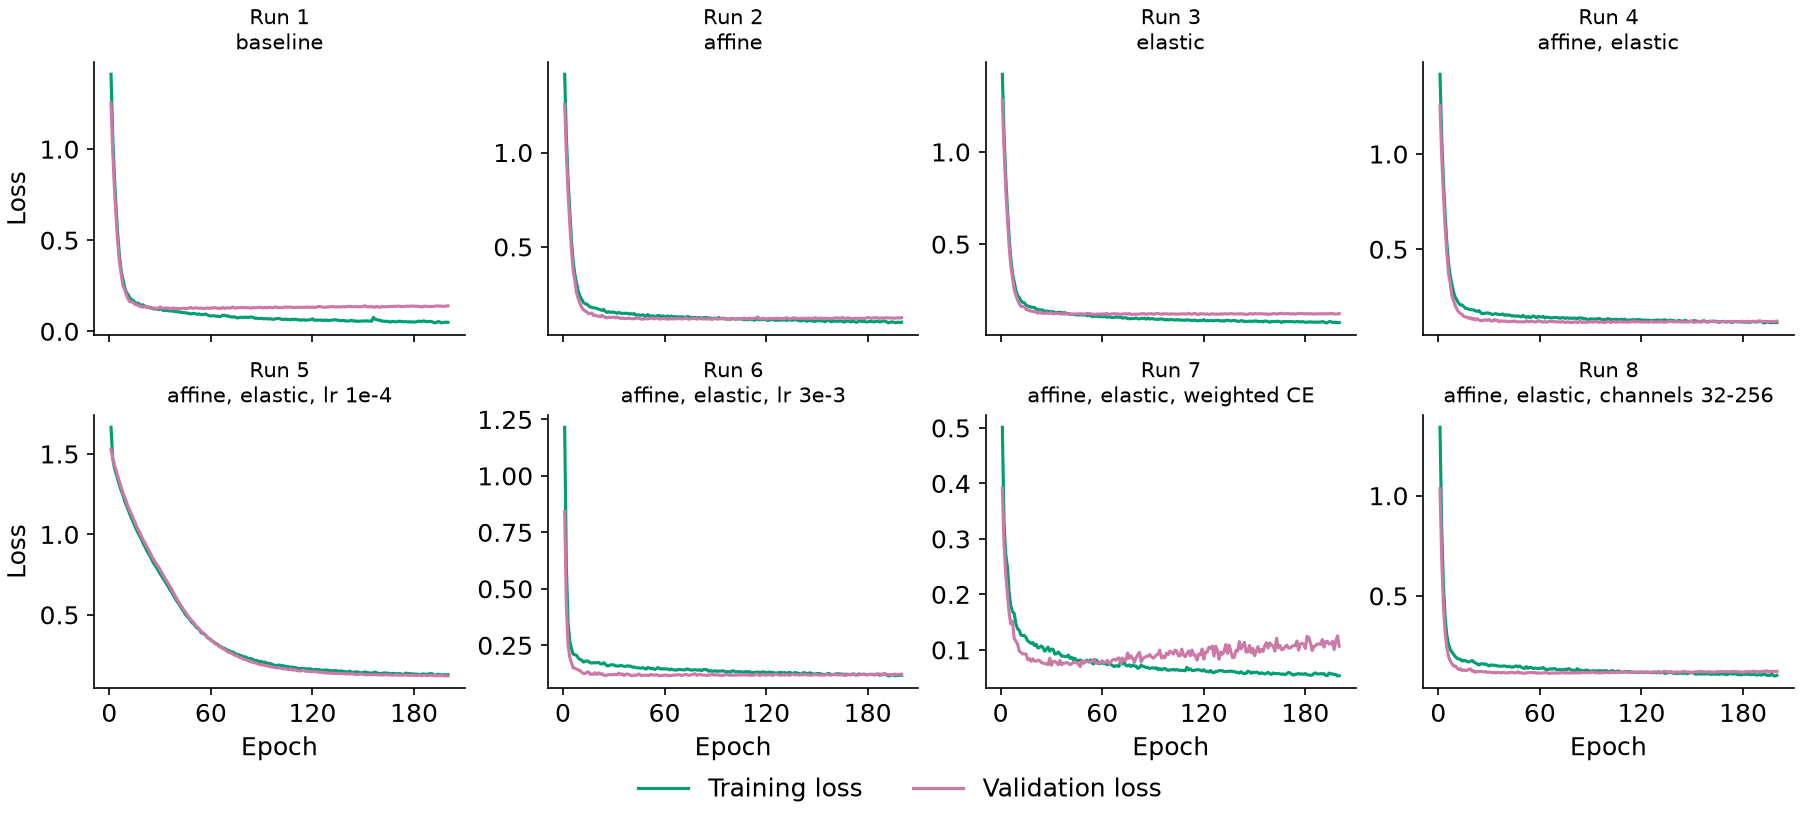

In [24]:
# Training and validation loss on the same axes, one panel per run
from matplotlib.ticker import MaxNLocator


def run_grid(draw_panel, ylabel, filename, sharey=False):
    """Draw one panel per run with a shared legend, and save the figure to the output folder."""
    with plt.rc_context({"font.size": 12}):
        fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharex=True, sharey=sharey, constrained_layout=True)
        for ax, (name, results) in zip(axes.flat, ALL_RESULTS.items()):
            draw_panel(ax, name)
            ax.set_title(f"Run {name[3]}\n{describe_overrides(results['overrides'])}", fontsize=10)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
            ax.spines[["top", "right"]].set_visible(False)
        for ax in axes[1]:
            ax.set_xlabel("Epoch")
        for ax in axes[:, 0]:
            ax.set_ylabel(ylabel)
        handles, labels = axes.flat[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside lower center", ncols=len(labels), frameon=False)
        fig.savefig(CFG["output_dir"] / filename, dpi=150)
        plt.show()


def _draw_loss(ax, name):
    epochs = ALL_HISTORIES[name]["epochs"]
    x = [e["epoch"] for e in epochs]
    ax.plot(x, [e["train_loss"] for e in epochs], color=LOSS_COLOURS["train"], label="Training loss")
    ax.plot(x, [e["val_loss"] for e in epochs], color=LOSS_COLOURS["val"], label="Validation loss")


run_grid(_draw_loss, "Loss", "loss_curves.png")

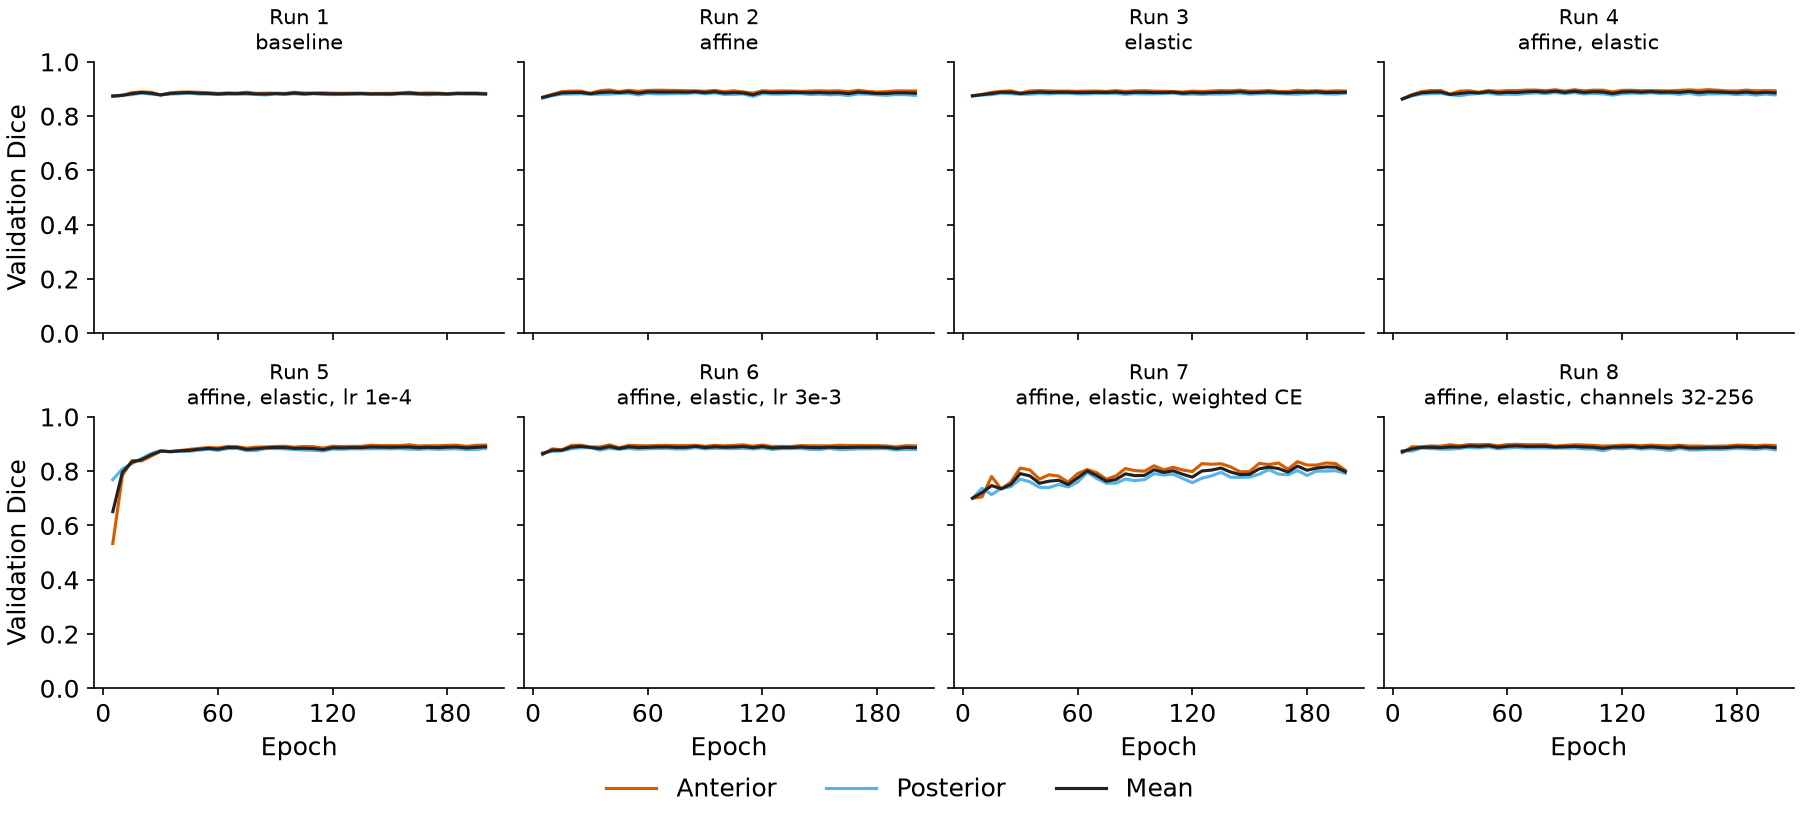

In [25]:
# Validation Dice vs epoch for every run
def _draw_dice(ax, name):
    measured = [e for e in ALL_HISTORIES[name]["epochs"] if e["val_dice"] is not None]
    x = [e["epoch"] for e in measured]
    ax.plot(x, [e["val_dice"]["anterior"] for e in measured], color=OVERLAY_COLOURS[1], label="Anterior")
    ax.plot(x, [e["val_dice"]["posterior"] for e in measured], color=OVERLAY_COLOURS[2], label="Posterior")
    ax.plot(x, [e["val_dice"]["mean"] for e in measured], color="#222222", label="Mean")
    ax.set_ylim(0, 1)


run_grid(_draw_dice, "Validation Dice", "val_dice_curves.png", sharey=True)

/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


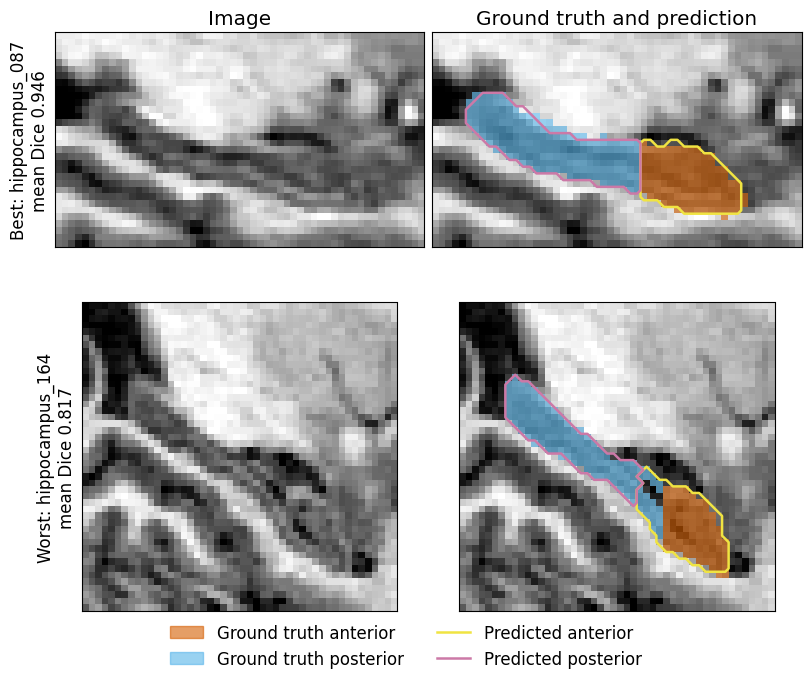

In [26]:
# Qualitative figure for the final model. The test cases are picked for display only; nothing here feeds a decision.
from matplotlib.lines import Line2D

final_results = ALL_RESULTS[FINAL_RUN]
final_cfg = {**CFG, **BASELINE, **final_results["overrides"]}
final_model = build_model(final_cfg)
_checkpoint = torch.load(CFG["output_dir"] / FINAL_RUN / "best.pt", map_location=CFG["device"], weights_only=True)
final_model.load_state_dict(_checkpoint["model"])
final_model.eval()

_ranked = sorted(final_results["test"]["per_case"], key=lambda row: row["mean"])
_shown = (("Best", _ranked[-1]), ("Worst", _ranked[0]))
_transform = get_transforms(final_cfg, train=False)
overlay_cmap = ListedColormap([OVERLAY_COLOURS[1], OVERLAY_COLOURS[2]])
# Outlines need colours that stand out against the filled ground truth underneath them
OUTLINE_COLOURS = {1: "#F0E442", 2: "#CC79A7"}  # predicted anterior, predicted posterior

with plt.rc_context({"font.size": 12}):
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=True)
    for row, (kind, case) in enumerate(_shown):
        item = _transform({"image": str(CFG["dataset_dir"] / "imagesTr" / case["case"]),
                           "label": str(CFG["dataset_dir"] / "labelsTr" / case["case"])})
        with torch.no_grad(), torch.autocast(device_type=CFG["device"], enabled=CFG["amp"]):
            logits = sliding_window_inference(item["image"].unsqueeze(0).to(CFG["device"]), roi_size=CFG["patch_size"],
                                              sw_batch_size=CFG["batch_size"], predictor=final_model,
                                              overlap=CFG["sw_overlap"])
        prediction = logits.argmax(dim=1)[0].cpu().numpy()
        image, label = item["image"][0].numpy(), item["label"][0].numpy()

        # Sagittal slice (RAS axis 0) at the middle of the hippocampus; this view shows both classes
        foreground_x = np.sort(np.where(label > 0)[0])
        slice_x = int(foreground_x[len(foreground_x) // 2])
        image_slice = image[slice_x].T
        vmin, vmax = np.percentile(image_slice, 1), np.percentile(image_slice, 99)

        for col in range(2):
            ax = axes[row, col]
            ax.imshow(image_slice, cmap="gray", origin="lower", vmin=vmin, vmax=vmax, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])

        # Right column: ground truth filled, prediction outlined on top
        ax = axes[row, 1]
        ax.imshow(np.ma.masked_equal(label[slice_x].T, 0), cmap=overlay_cmap, origin="lower",
                  vmin=1, vmax=2, alpha=0.6, interpolation="nearest")
        prediction_slice = prediction[slice_x].T
        for k, colour in OUTLINE_COLOURS.items():
            if (prediction_slice == k).any():  # a class can be absent from this slice
                ax.contour(prediction_slice == k, levels=[0.5], colors=colour, linewidths=1.8)

        case_id = case["case"].removesuffix(".nii.gz")
        axes[row, 0].set_ylabel(f"{kind}: {case_id}\nmean Dice {case['mean']:.3f}")

    axes[0, 0].set_title("Image")
    axes[0, 1].set_title("Ground truth and prediction")
    handles = [Patch(color=OVERLAY_COLOURS[k], alpha=0.6, label=f"Ground truth {LABEL_MAP[k]}") for k in OVERLAY_COLOURS]
    handles += [Line2D([], [], color=OUTLINE_COLOURS[k], linewidth=1.8, label=f"Predicted {LABEL_MAP[k]}") for k in OUTLINE_COLOURS]
    fig.legend(handles=handles, loc="outside lower center", ncols=2, frameon=False)
    fig.savefig(CFG["output_dir"] / "qualitative_cases.png", dpi=150)
    plt.show()

In [27]:
# Full mode only: copy the summary files to figures/. Dev mode never touches figures/.
SUMMARY_FILES = ["results_table.md", "loss_curves.png", "val_dice_curves.png", "qualitative_cases.png"]

if CFG["mode"] == "full":
    CFG["figures_dir"].mkdir(parents=True, exist_ok=True)
    for filename in SUMMARY_FILES:
        shutil.copy2(CFG["output_dir"] / filename, CFG["figures_dir"] / filename)
    print(f"Copied {len(SUMMARY_FILES)} files to {CFG['figures_dir']}")
    if IS_COLAB:
        print("Reminder: copy this folder and outputs/full from Drive to the local project.")
else:
    print("Dev mode: figures/ was not touched.")

Copied 4 files to /content/drive/MyDrive/decathlon/figures
Reminder: copy this folder and outputs/full from Drive to the local project.
